# Personal Loan Prediction

In [1]:
# Importing Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
print('Libraries imported')

Libraries imported


In [2]:
# Gathering Data
bank_data = pd.read_csv('Bank_Personal_Loan_Modelling.csv')
data = bank_data.copy()

In [3]:
data.corr()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,1.000000,-0.008473,-0.008326,-0.017695,0.013432,-0.016797,-0.024675,0.021463,-0.013920,-0.024801,-0.016972,-0.006909,-0.002528,0.017028
Age,-0.008473,1.000000,0.994215,-0.055269,-0.029216,-0.046418,-0.052012,0.041334,-0.012539,-0.007726,-0.000436,0.008043,0.013702,0.007681
Experience,-0.008326,0.994215,1.000000,-0.046574,-0.028626,-0.052563,-0.050077,0.013152,-0.010582,-0.007413,-0.001232,0.010353,0.013898,0.008967
Income,-0.017695,-0.055269,-0.046574,1.000000,-0.016410,-0.157501,0.645984,-0.187524,0.206806,0.502462,-0.002616,0.169738,0.014206,-0.002385
ZIP Code,0.013432,-0.029216,-0.028626,-0.016410,1.000000,0.011778,-0.004061,-0.017377,0.007383,0.000107,0.004704,0.019972,0.016990,0.007691
Family,-0.016797,-0.046418,-0.052563,-0.157501,0.011778,1.000000,-0.109275,0.064929,-0.020445,0.061367,0.019994,0.014110,0.010354,0.011588
CCAvg,-0.024675,-0.052012,-0.050077,0.645984,-0.004061,-0.109275,1.000000,-0.136124,0.109905,0.366889,0.015086,0.136534,-0.003611,-0.006689
Education,0.021463,0.041334,0.013152,-0.187524,-0.017377,0.064929,-0.136124,1.000000,-0.033327,0.136722,-0.010812,0.013934,-0.015004,-0.011014
Mortgage,-0.013920,-0.012539,-0.010582,0.206806,0.007383,-0.020445,0.109905,-0.033327,1.000000,0.142095,-0.005411,0.089311,-0.005995,-0.007231
Personal Loan,-0.024801,-0.007726,-0.007413,0.502462,0.000107,0.061367,0.366889,0.136722,0.142095,1.000000,0.021954,0.316355,0.006278,0.002802


In [3]:
# Data Shape
print('Shape of data{}'.format(data.shape))
print("Number of rows:{}".format(data.shape[0]))
print("Number of columns:{}".format(data.shape[1]))

Shape of data(5000, 14)
Number of rows:5000
Number of columns:14


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


There are no any categorical columns.

# Observation:

   There are 13 features and 5000 entires, all non-null. all features are numerical features, and of them, Education, Mortagage, Securities Account, CD Account, Online,Credit Card, Personal Loan is a numerical categorical feature.

In [5]:
# Missings And duplicates values
print(data.isna().sum().sort_values(ascending = False))
print('duplicate values in  data are' ,data.duplicated().sum() )
print('duplicates dropped')

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64
duplicate values in  data are 0
duplicates dropped


There is no any missings values and also no any duplicaltes values.

In [6]:
data.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [7]:
data.columns

Index(['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object')

In [6]:
# Dropping Unnecessary columns 'ID' and 'ZIP Code'
data.drop(columns = ['ID' , 'ZIP Code'] ,  axis = 1 , inplace =True)

In [7]:
# Create counts of df for plotting categorical variables
loan = np.unique(data['Personal Loan'], return_counts=True)
print('loan = {}\n'.format(loan))

loan = (array([0, 1], dtype=int64), array([4520,  480], dtype=int64))



In [8]:
# Create fontdicts for formatting figure text
axtitle_dict = {'family': 'serif','color':  'darkred','weight': 'bold','size': 16}
axlab_dict = {'family': 'serif', 'color': 'black','size': 14}

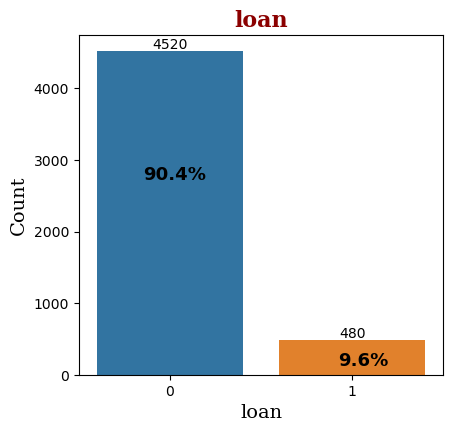

In [9]:
# Display a frequency distribution for Personal Loan. 
fig = plt.figure(figsize=[16,15]);
ax1 = fig.add_subplot(3, 3, 2);
sns.barplot(x=list(loan[0]), y=list(loan[1]), ax=ax1 );
ax1.text(0.2, 2800, '{}%' .format(str(round(loan[1][0]/sum(loan[1])*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
ax1.text(1.2, 200, '{}%' .format(str(round(loan[1][1]/sum(loan[1])*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
ax1.set_title('loan', fontdict=axtitle_dict);
ax1.set_xlabel('loan', fontdict=axlab_dict);
ax1.set_ylabel('Count', fontdict=axlab_dict);
ax1.bar_label(ax1.containers[0])
plt.show()

Data is Highly Imblanaced majority of the data are class 0.Imblanaced ratio is 90:10.out of 5000 data 4520 is for not opting personal loan and 480 is for personal loan.

In [4]:
# Filtering Numericals and Categoricals columns:

categ_columns = []
for col in data.columns:
    if data[col].nunique()<=5:
        if col!='Personal Loan':
            categ_columns.append(col) 
print('categ numericals columns are {}'.format(categ_columns))

categ numericals columns are ['Family', 'Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


In [5]:
Num_cols = [col for col in data.columns if col not in categ_columns]
print('numericals columns are {}'.format(Num_cols)) 
Num_cols.pop()
Num_cols

numericals columns are ['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'CCAvg', 'Mortgage', 'Personal Loan']


['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'CCAvg', 'Mortgage']

# EDA

In [14]:
# Create counts of df for plotting categorical variables
Online_account = np.unique(data['Online'], return_counts=True)
print('Online_account = {}\n'.format(Online_account))

Online_account = (array([0, 1], dtype=int64), array([2016, 2984], dtype=int64))



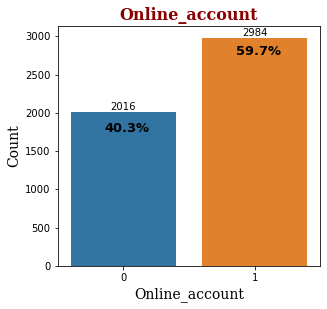

In [15]:
fig = plt.figure(figsize=[16,15]);
ax1 = fig.add_subplot(3, 3, 2);
sns.barplot(x=list(Online_account[0]), y=list(Online_account[1]), ax=ax1 );
ax1.text(0.2, 1800, '{}%' .format(str(round(Online_account[1][0]/sum(Online_account[1])*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
ax1.text(1.2, 2800, '{}%' .format(str(round(Online_account[1][1]/sum(Online_account[1])*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
ax1.set_title('Online_account', fontdict=axtitle_dict);
ax1.set_xlabel('Online_account', fontdict=axlab_dict);
ax1.set_ylabel('Count', fontdict=axlab_dict);
ax1.bar_label(ax1.containers[0])
plt.show()

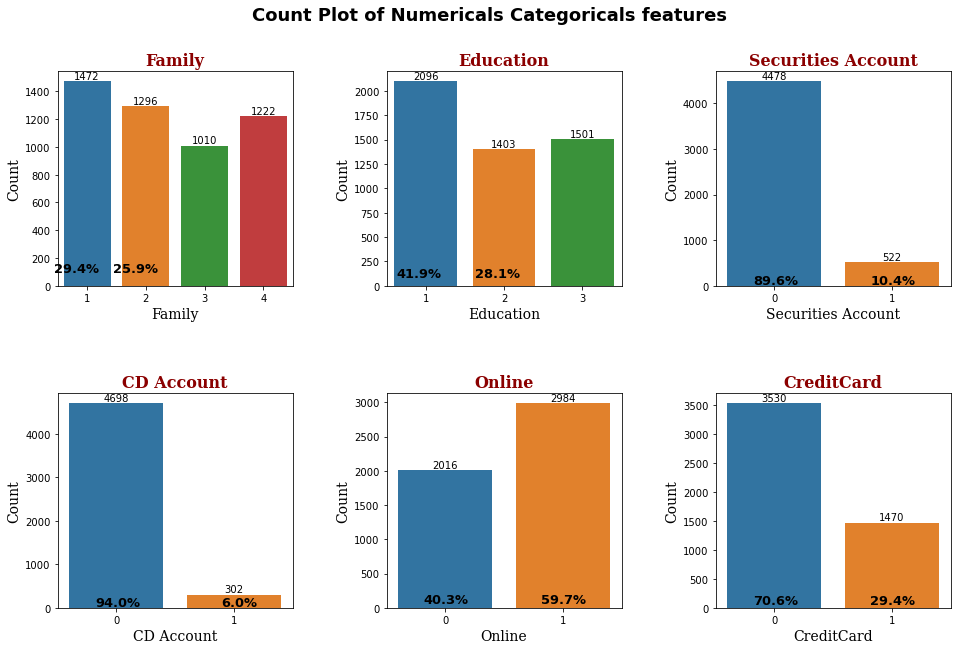

In [16]:
# Unvariate Analysis
fig = plt.figure(figsize=[16,15])
fig.suptitle('Count Plot of Numericals Categoricals features', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i , columns in enumerate(categ_columns):
    input = np.unique(data[columns] , return_counts = True)
    col= 'input'
    ax1 = fig.add_subplot(3, 3, i+1);
    ax1 = sns.barplot(x=list(eval(f'{col}[0]')), y=list(eval(f'{col}[1]')))
    #The below two lines of codes are used for percentage values.
    ax1.text(0.2, 120, '{}%' .format(str(round(eval(f'{col}[1][0]')/sum(eval(f'{col}[1]'))*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
    ax1.text(1.2, 120, '{}%' .format(str(round(eval(f'{col}[1][1]')/sum(eval(f'{col}[1]'))*100,1))), ha='right', va='center', size=13, fontdict={'weight': 'bold'})
    ax1.set_title(f'{columns}', fontdict=axtitle_dict)
    ax1.set_xlabel(f'{columns}', fontdict=axlab_dict)
    ax1.set_ylabel('Count', fontdict=axlab_dict)
    ax1.bar_label(ax1.containers[0])

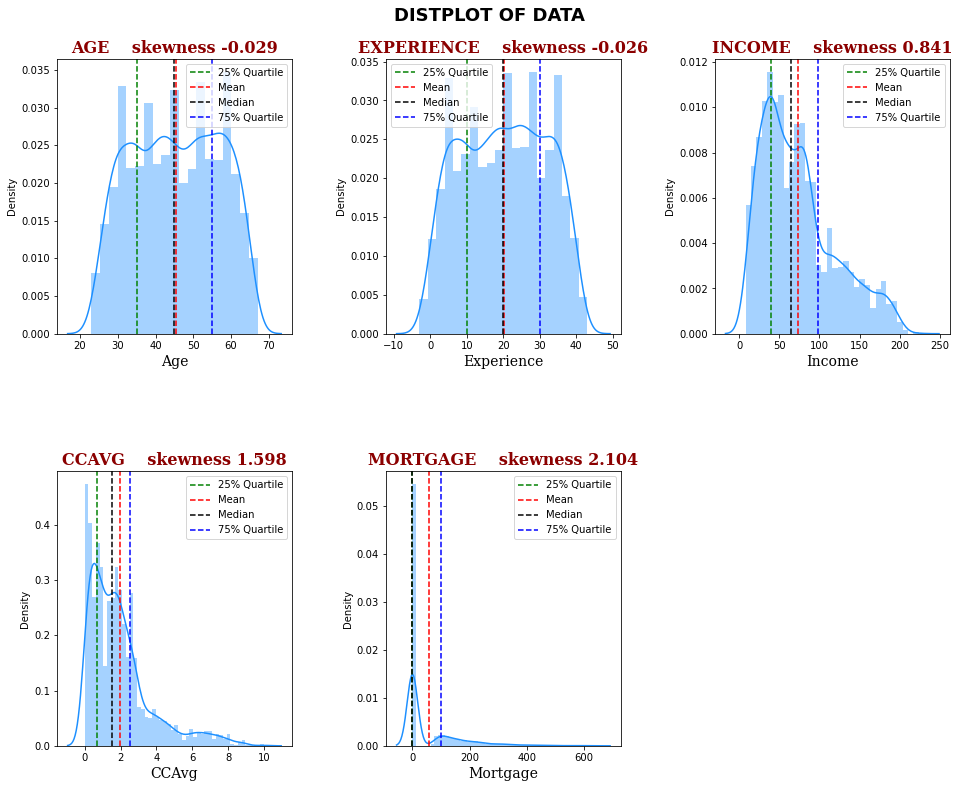

In [17]:
# Distplot
# Create figure with 3 x 3 grid of subplots
fig = plt.figure(figsize=[16,12])
fig.suptitle('DISTPLOT OF DATA', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate(Num_cols):
    ax = fig.add_subplot(2, 3, i+1)
    ax = sns.distplot(data[col],  color='dodgerblue')
    ax.axvline(data[col].quantile(q=0.25),color='green',linestyle='--',label='25% Quartile')
    ax.axvline(data[col].mean(),color='red',linestyle='--',label='Mean')
    ax.axvline(data[col].median(),color='black',linestyle='--',label='Median')
    ax.axvline(data[col].quantile(q=0.75),color='blue',linestyle='--',label='75% Quartile')
    # ax.text('skewness: {}' .format(str(round(df[col].skew(),3))), ha='right', va='center', size=11)
    ax.set_xlabel(f'{col}', fontdict=axlab_dict)
    ax.set_title(f'{col.upper()}    skewness {round(data[col].skew(),3)}', fontdict=axtitle_dict)
    ax.legend(fontsize=10) 

In [18]:
colours = ['forestgreen','dodgerblue','goldenrod', 'coral' , 'silver' , 'gold' , 'dodgerblue'];

In [6]:
# Outliers Detection
# Check of outliers by applying the IQR method checking if values are way outside the IQR borders.
# numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
data_num = data[Num_cols]
data_num.describe()

Q1 = data_num.quantile(0.25)
Q3 = data_num.quantile(0.75)
IQR = Q3 - Q1
IQR
((data_num < (Q1 - 1.5 * IQR)) | (data_num > (Q3 + 1.5 * IQR))).any()

ID            False
Age           False
Experience    False
Income         True
ZIP Code       True
CCAvg          True
Mortgage       True
dtype: bool

Income , CCAvg , Mortgage have outliers.

# Visualization of outliers using box plot

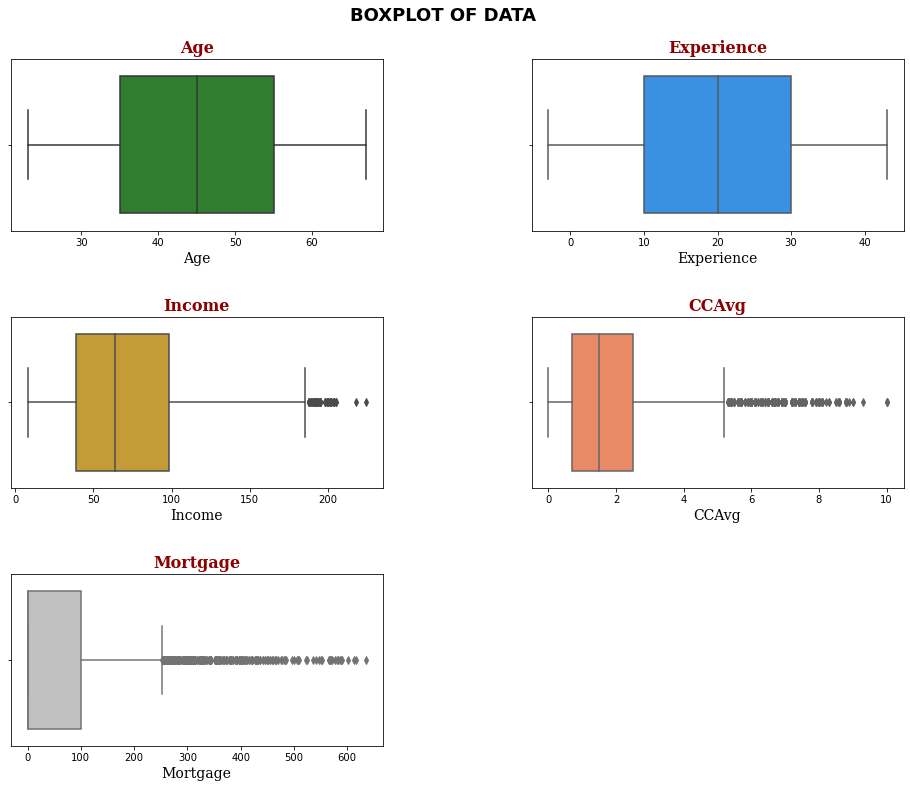

In [20]:
# Create figure with 3 x 3 grid of subplots
fig = plt.figure(figsize=[16,12])
fig.suptitle('BOXPLOT OF DATA', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate(Num_cols):  
    ax1 = fig.add_subplot(3, 2, i+1);
    ax1 = sns.boxplot(data = data, x=col ,  color= colours[i]);
 
    ax1.set_title(f'{col}', fontdict=axtitle_dict) 
    ax1.set_xlabel(f'{col}', fontdict=axlab_dict)

# Outliers Detection

In [7]:
# Finding the IQR For Budget columns
dict = {}
for col in ['Income' , 'CCAvg' , 'Mortgage']:
    percentile25 = data[col].quantile(0.25)
    percentile75 = data[col].quantile(0.75)
    IQR  = percentile75 - percentile25 
    upper_limit = percentile75 + 1.5 * IQR 
    lower_limit = percentile25 - 1.5 * IQR
    dict['upper_limit'+ '_' + col] = upper_limit
    dict['lower_limit'+ '_' + col] = lower_limit 

In above code cell we just created a dictionary to keep upper_limit and lower_limit of Income, CCAvg, Mortgage.

In [8]:
dict

{'upper_limit_Income': np.float64(186.5),
 'lower_limit_Income': np.float64(-49.5),
 'upper_limit_CCAvg': np.float64(5.2),
 'lower_limit_CCAvg': np.float64(-2.0),
 'upper_limit_Mortgage': np.float64(252.5),
 'lower_limit_Mortgage': np.float64(-151.5)}

In [23]:
for col in ['Income' , 'CCAvg' , 'Mortgage']:
    print('There are total {} Customers data which {} are less than lower limit.'.format(len(data[data[col] < dict['lower_limit_' + col]] ) , col))
    print('There are total {} Customers data which {} are more than upper limit.'.format(len(data[data[col] > dict['upper_limit_' + col]] ) , col))

There are total 0 Customers data which Income are less than lower limit.
There are total 96 Customers data which Income are more than upper limit.
There are total 0 Customers data which CCAvg are less than lower limit.
There are total 324 Customers data which CCAvg are more than upper limit.
There are total 0 Customers data which Mortgage are less than lower limit.
There are total 291 Customers data which Mortgage are more than upper limit.


Capping Income , CCAvg and Mortgage with upper limit and lower limit.

In [24]:
for col in ['Income' , 'CCAvg' , 'Mortgage']:
    data[col] = np.where(
        data[col] > dict['upper_limit_' + col],
        dict['upper_limit_' + col],
        np.where(
            data[col] < dict['lower_limit_' + col],
            dict['lower_limit_' + col],
            data[col]  
        )
    )

After Outliers treatment


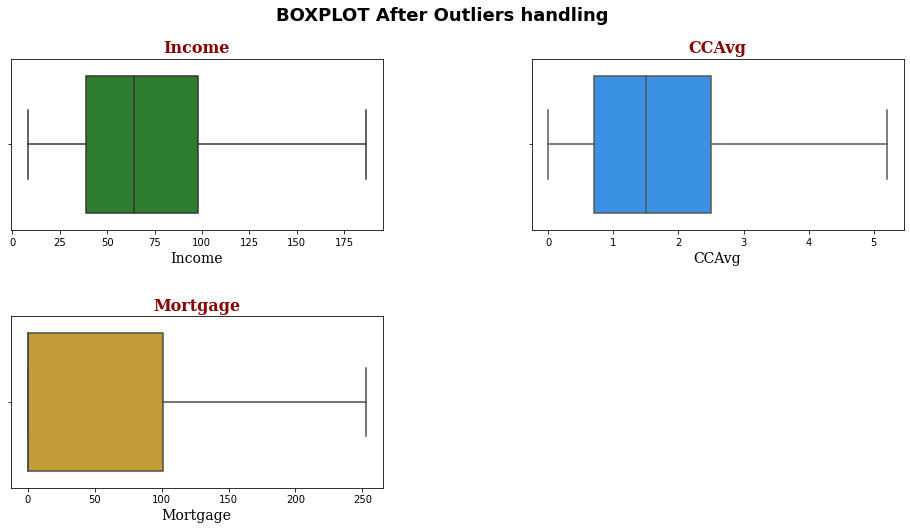

In [25]:
# Create figure with 3 x 3 grid of subplots
fig = plt.figure(figsize=[16,12])
fig.suptitle('BOXPLOT After Outliers handling', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate( ['Income' , 'CCAvg' , 'Mortgage']):  
    ax1 = fig.add_subplot(3, 2, i+1);
    ax1 = sns.boxplot(data = data, x=col ,  color= colours[i]);
 
    ax1.set_title(f'{col}', fontdict=axtitle_dict) 
    ax1.set_xlabel(f'{col}', fontdict=axlab_dict)

# Bivariate analysis

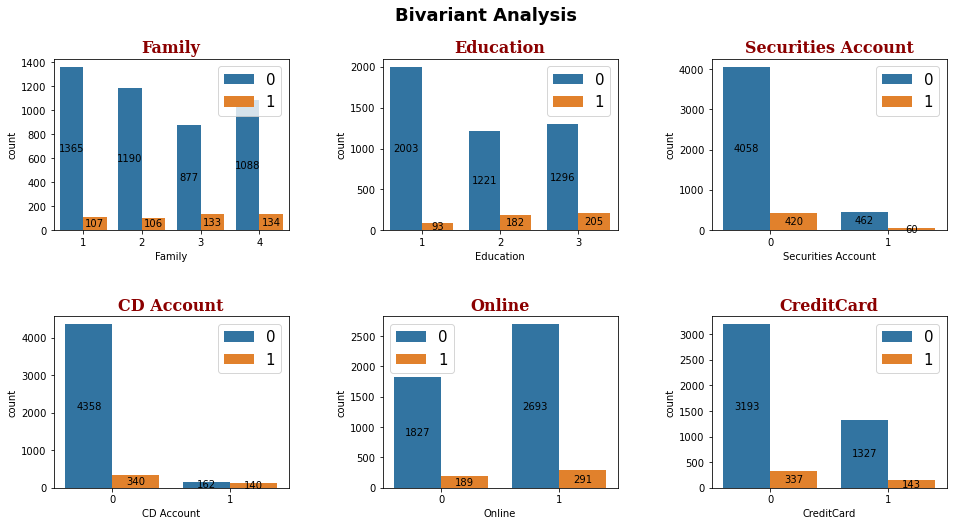

In [26]:
# Create figure with 3 x 3 grid of subplots
fig = plt.figure(figsize=[16,12])
fig.suptitle('Bivariant Analysis', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate(categ_columns):
    a = fig.add_subplot(3, 3, i+1)
    a=sns.countplot(x = data[col] , ax=a , hue = data['Personal Loan'] )
    a.set_title(col , fontdict=axtitle_dict)
    a.bar_label(a.containers[0] , label_type='center') 
    a.bar_label(a.containers[1] , label_type='center')
    a.legend(fontsize=15)

# Plot Insights:

   * Highly educated customers seem to much interested in personal loan than lower educated customers.

   * Customers without securites account seem to more interseted than not securities account customers in personal loan.

   * Customers with CD Account have higher probablity to take personal loan.in bar graph you can clearly see out of 163 cd account customers 140 is taken personal loan.

   * Customers with Online internet banking are more intersted than non online customers in personal loan.

   * Customers without Credit Card have much higher chance to take personal loan.

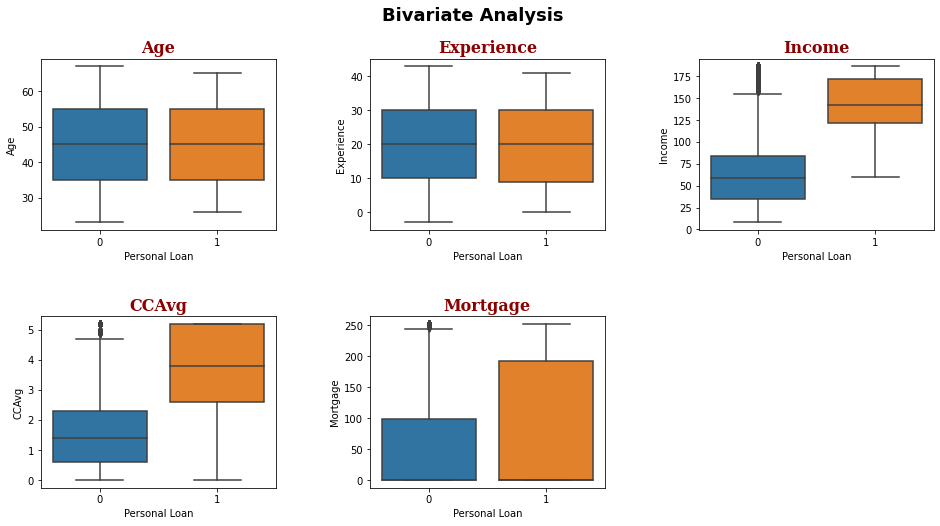

In [27]:
# Create figure with 3 x 3 grid of subplots
fig = plt.figure(figsize=[16,12])
fig.suptitle('Bivariate Analysis', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate(Num_cols):
    a = fig.add_subplot(3, 3, i+1)
    a=sns.boxplot(x = 'Personal Loan' , y =col , ax=a  , data = data )
    a.set_title(col , fontdict=axtitle_dict)

# Plot Insights:

 * Customers with personal loan Have Much higher Income with a median of 145 USD compared to a median of customers not opting for personal loan of median 55 USD.

 * Customers who opted for personal loan have higher credit card avg spending with median 4 USD.

 * Customers who opted for personal loan have slightly higher mortgate.

 * Age and Experience doesn't have much effect on personal loan.

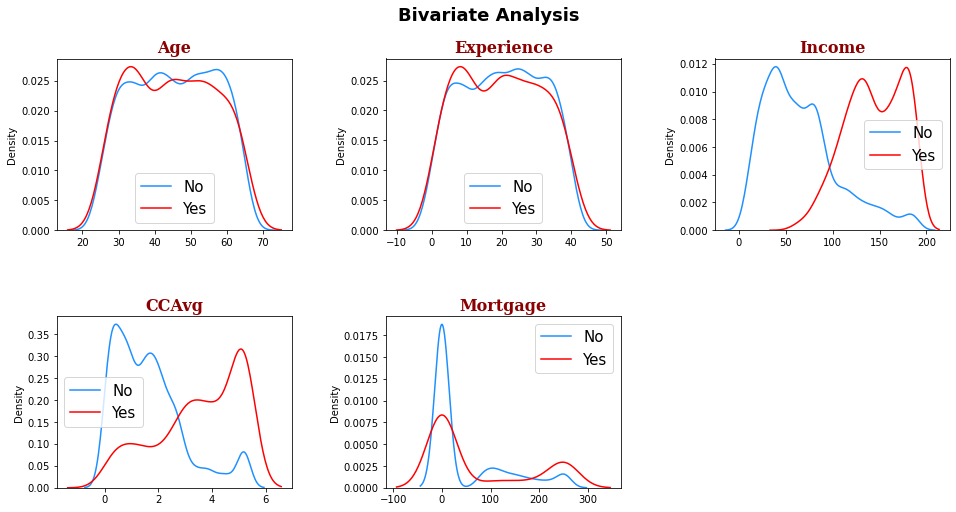

In [28]:
fig = plt.figure(figsize=[16,12])
fig.suptitle('Bivariate Analysis', fontsize=18, fontweight='bold')
fig.subplots_adjust(top=0.92);
fig.subplots_adjust(hspace=0.5, wspace=0.4);
for i ,col in enumerate(Num_cols):
    a = fig.add_subplot(3, 3, i+1)
    
    sns.distplot(x =data[data['Personal Loan']==0][col],  color='dodgerblue' , ax=a ,  hist =False)
    sns.distplot(x =data[data['Personal Loan']==1][col],  color='red' , ax=a , hist =False) 
    a.set_title(col , fontdict=axtitle_dict)    
    labels = ['No' , 'Yes']
    a.legend( labels  , fontsize = 15)

# Creating Dummies for Categ columns

In [29]:
dum_data = pd.get_dummies(data , columns = categ_columns)
dum_data.head()

,Age,Experience,Income,CCAvg,Mortgage,Personal Loan,Family_1,Family_2,Family_3,Family_4,...,Education_2,Education_3,Securities Account_0,Securities Account_1,CD Account_0,CD Account_1,Online_0,Online_1,CreditCard_0,CreditCard_1
0,25,1,49.0,1.6,0.0,0,0,0,0,1,...,0,0,0,1,1,0,1,0,1,0
1,45,19,34.0,1.5,0.0,0,0,0,1,0,...,0,0,0,1,1,0,1,0,1,0
2,39,15,11.0,1.0,0.0,0,1,0,0,0,...,0,0,1,0,1,0,1,0,1,0
3,35,9,100.0,2.7,0.0,0,1,0,0,0,...,1,0,1,0,1,0,1,0,1,0
4,35,8,45.0,1.0,0.0,0,0,0,0,1,...,1,0,1,0,1,0,1,0,0,1


In [3]:
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [4]:
data.columns

Index(['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object')

In [3]:
from sklearn.preprocessing import LabelEncoder
labelencoder=LabelEncoder()

In [4]:
data['Family']=labelencoder.fit_transform(data['Family'])
data['Education']=labelencoder.fit_transform(data['Education'])
data['Securities Account']=labelencoder.fit_transform(data['Securities Account'])
data['CD Account']=labelencoder.fit_transform(data['CD Account'])
data['Online']=labelencoder.fit_transform(data['Online'])
data['CreditCard']=labelencoder.fit_transform(data['CreditCard'])

In [5]:
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,3,1.6,0,0,0,1,0,0,0
1,2,45,19,34,90089,2,1.5,0,0,0,1,0,0,0
2,3,39,15,11,94720,0,1.0,0,0,0,0,0,0,0
3,4,35,9,100,94112,0,2.7,1,0,0,0,0,0,0
4,5,35,8,45,91330,3,1.0,1,0,0,0,0,0,1


# Correlation Analysis

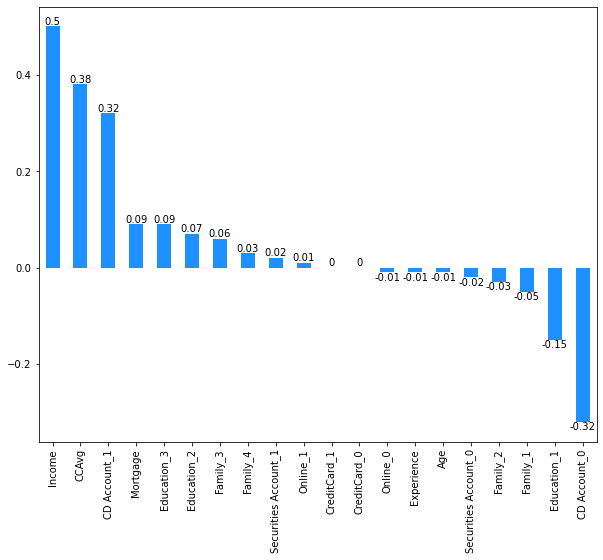

In [30]:
ax = round(dum_data.corr()['Personal Loan'].sort_values(ascending = False)[1:] ,2 ).plot(kind = 'bar' ,color='dodgerblue' , figsize = (10,8))
ax.bar_label(ax.containers[0])
plt.show()

# Derived Insight:

HIGH Possibility to take personal loan seen in case of Higher Income, High Credit Cards Spending, and Customers with CD Account,

HIGH Possibility to take personal loan is seen in case of Without CD Account, Lower Eduction and With One Family Members

Factors like Credit Cards Availability, Availability of Online Internet Banking have alomost NO impact on personal loan.

This is also evident from the Heatmap below

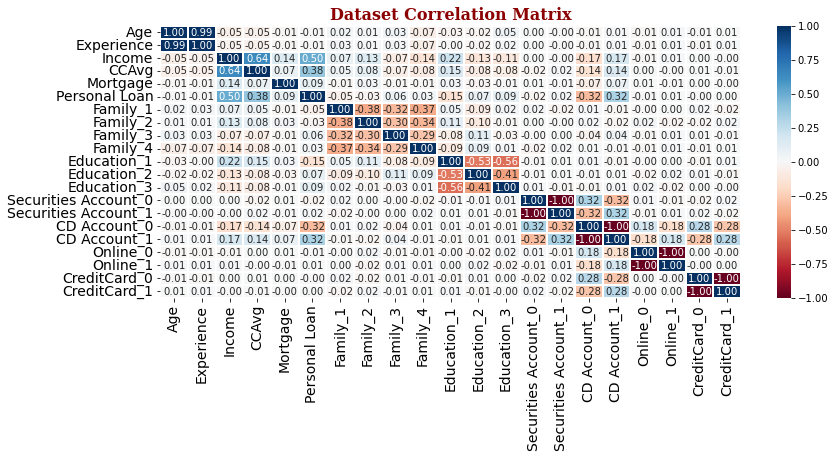

In [31]:
# Heatmap
# Plot correlation matrix heatmap
fig, ax = plt.subplots(figsize=[13,5])
sns.heatmap(dum_data.corr(), ax=ax,  annot=True, linewidths=0.05, fmt= '.2f',cmap='RdBu')
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_title('Dataset Correlation Matrix', fontdict=axtitle_dict)
fig.show()

# Modelling

In [32]:
X = dum_data.drop('Personal Loan' , 1 )
y = dum_data['Personal Loan']
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X , y  ,test_size = 0.33 , random_state = 42)
X_train.shape , y_train.shape , X_test.shape , y_test.shape 

((3350, 20), (3350,), (1650, 20), (1650,))

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn import metrics
from sklearn.metrics import recall_score , classification_report , confusion_matrix  ,roc_curve , roc_auc_score , accuracy_score
from sklearn.metrics import precision_recall_curve , auc ,f1_score , plot_confusion_matrix , precision_score , recall_score
from sklearn.tree import DecisionTreeClassifier

The models used include:

   * K Nearest Neighbors - fast, simple and instance-based
   * Logistic Regression - fast and linear model
   * Random Forest - slower but accurate ensemble model based on decision trees
   * Support Vector Machines - slower but accurate model used here in the non-linear form

In [34]:
model_list = []
accuracy_list = []
recall_list = []
precision_list = []
f1_score_list= [] 

In [35]:
def Model_features(X_train , y_train , X_test , y_test , y_pred , classifier  , model_name):
#     fig ,ax = plt.subplots(figsize = (7,6))
    accuracy , precision , recall , f1_s = round(accuracy_score(y_test , y_pred) , 3) , round(precision_score(y_test, y_pred, average="micro")  ,3), round(recall_score(y_test , y_pred) ,3), round(f1_score(y_test , y_pred) , 3)
    print(f'Accuracy Score is :{accuracy}')
    print(f'Precision Score is :{precision}')
    print(f'Recall Score is :{recall}')
    print(f'f1  Score is :{f1_s}')
    model_list.append(model_name)
    accuracy_list.append(accuracy)
    recall_list.append(recall)
    precision_list.append(precision)
    f1_score_list.append(f1_s)
    print(metrics.classification_report(y_test, y_pred)) 

# Features Importanaces

In [36]:
# Define a function that plots the feature weights for a classifier.
def feature_weights(X_df, classifier, classifier_name):
    weights = round(pd.Series(classifier.coef_[0], index=X_df.columns.values).sort_values(ascending=False) ,2 )
    top_weights_selected = weights[:5]
    plt.figure(figsize=(7,6))
    plt.tick_params(labelsize=10)#plt.xlabel(fontsize=10)
    plt.title(f'{classifier_name} - Top 5 Features')
    ax = top_weights_selected.plot(kind="bar")
    ax.bar_label(ax.containers[0])
    
    return print("")


In [37]:
def confusion_matrix_plot(X_test , y_test , classifier ,classifier_name):
    ax = plot_confusion_matrix(classifier, X_test, y_test, display_labels=["No Personal Loan", "Personal Loan"], cmap=plt.cm.Blues, normalize='true')

# Logistic Regression

In [38]:
model_lr= LogisticRegression(random_state=0)  
model_lr.fit(X_train, y_train) 
y_pred = model_lr.predict(X_test)
model_lr.score(X_test , y_test)

0.9666666666666667

Accuracy Score is :0.967
Precision Score is :0.967
Recall Score is :0.747
f1  Score is :0.822
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1480
           1       0.91      0.75      0.82       170

    accuracy                           0.97      1650
   macro avg       0.94      0.87      0.90      1650
weighted avg       0.97      0.97      0.97      1650




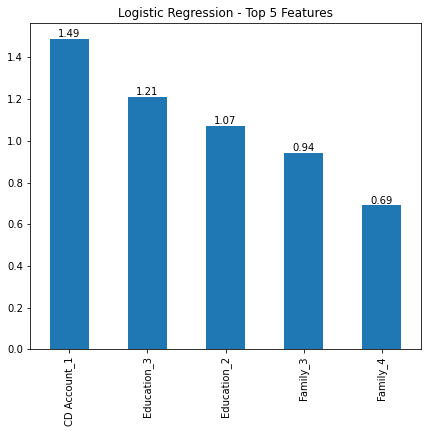

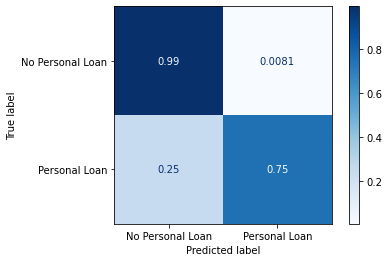

In [39]:
Model_features(X_train , y_train , X_test , y_test  , y_pred , model_lr , "Logistic Reegression")   
feature_weights(X_train , model_lr , "Logistic Regression")
confusion_matrix_plot(X_test , y_test , model_lr , "Logistic Regression")

# KNN Classifier

In [40]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
knn.score(X_test , y_test)

0.8927272727272727

Accuracy Score is :0.893
Precision Score is :0.893
Recall Score is :0.212
f1  Score is :0.289
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      1480
           1       0.46      0.21      0.29       170

    accuracy                           0.89      1650
   macro avg       0.69      0.59      0.62      1650
weighted avg       0.87      0.89      0.87      1650



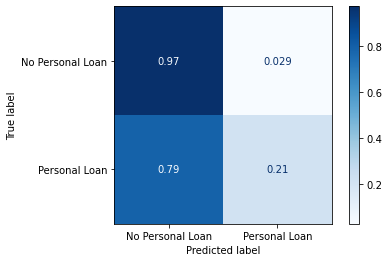

In [41]:
Model_features(X_train , y_train , X_test , y_test  , y_pred , knn , "Knn Classifier")   
confusion_matrix_plot(X_test , y_test , knn , "Knn Classifier")

# Random Forest Classifier

In [42]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
rf.score(X_test , y_test) 

0.990909090909091

Accuracy Score is :0.991
Precision Score is :0.991
Recall Score is :0.918
f1  Score is :0.954
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1480
           1       0.99      0.92      0.95       170

    accuracy                           0.99      1650
   macro avg       0.99      0.96      0.97      1650
weighted avg       0.99      0.99      0.99      1650



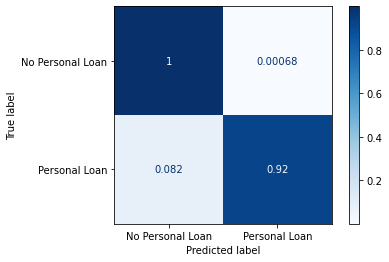

In [43]:
Model_features(X_train , y_train , X_test , y_test  , y_pred , rf , "Random Forest Classifier")   
confusion_matrix_plot(X_test , y_test , rf , "Random Forest Classifier")

# Support Vector Machine

In [44]:
svm = SVC(kernel='rbf', probability=True) 
svm.fit(X_train,y_train)

# Make predictions (classes and probabilities) with the trained model on the test set.
y_pred = svm.predict(X_test)
svm.score(X_test , y_test)  

0.9

Accuracy Score is :0.9
Precision Score is :0.9
Recall Score is :0.124
f1  Score is :0.203
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      1480
           1       0.57      0.12      0.20       170

    accuracy                           0.90      1650
   macro avg       0.74      0.56      0.57      1650
weighted avg       0.87      0.90      0.87      1650



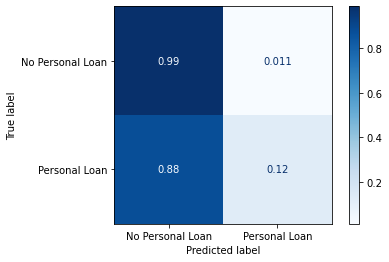

In [45]:
Model_features(X_train , y_train , X_test , y_test  , y_pred , svm , "Support Vector Machine")   
confusion_matrix_plot(X_test , y_test , svm , "Support Vector Machine")

# DecisionTreeClassifier

In [46]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)
y_pred = dtc.predict(X_test)
dtc.score(X_test , y_test) 

0.9824242424242424

Accuracy Score is :0.982
Precision Score is :0.982
Recall Score is :0.912
f1  Score is :0.914
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1480
           1       0.92      0.91      0.91       170

    accuracy                           0.98      1650
   macro avg       0.95      0.95      0.95      1650
weighted avg       0.98      0.98      0.98      1650



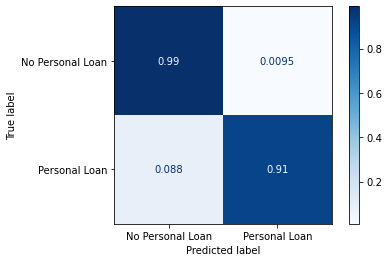

In [47]:
Model_features(X_train , y_train , X_test , y_test  , y_pred , dtc , "Decision Tree Classifier")   
confusion_matrix_plot(X_test , y_test , dtc , "Decision Tree Classifier")

In [48]:
dict = {'Model':model_list, 'Accuracy':accuracy_list , 'Precision':precision_list , 'f1_score':f1_score_list , 'Recall':recall_list}
model_data = pd.DataFrame(dict).sort_values(ascending = False , by = 'Accuracy')
model_data

,Model,Accuracy,Precision,f1_score,Recall
2,Random Forest Classifier,0.991,0.991,0.954,0.918
4,Decision Tree Classifier,0.982,0.982,0.914,0.912
0,Logistic Reegression,0.967,0.967,0.822,0.747
3,Support Vector Machine,0.900,0.900,0.203,0.124
1,Knn Classifier,0.893,0.893,0.289,0.212
